In [2]:
from pathlib import Path

import pandas as pd
import scanpy as sc
from scipy.stats import median_abs_deviation

DIR_PROCESADOS = Path("../data/processed")
DIR_FIGURAS = Path("../results/figuras")
DIR_TABLAS = Path("../results/tablas")

adata = sc.read_h5ad(DIR_PROCESADOS / "01_crudo.h5ad")
adata

AnnData object with n_obs × n_vars = 24746 × 36601
    obs: 'donante', 'condicion', 'muestra'
    var: 'gene_ids', 'feature_types'
    layers: None (.X)

In [3]:
adata.var["mt"] = adata.var_names.str.startswith("MT-")
adata.var["ribo"] = adata.var_names.str.startswith(("RPS", "RPL"))
adata.var["hb"] = adata.var_names.str.contains("^HB[^(P)]")

sc.pp.calculate_qc_metrics(adata, qc_vars=["mt", "ribo", "hb"],
                           percent_top=None, log1p=True, inplace=True)
adata.obs.columns

Index(['donante', 'condicion', 'muestra', 'n_genes_by_counts',
       'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts',
       'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt',
       'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo',
       'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb'],
      dtype='str')

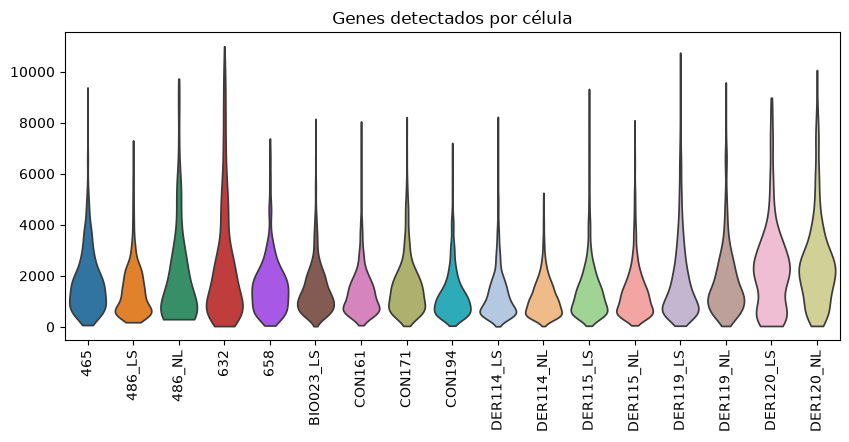

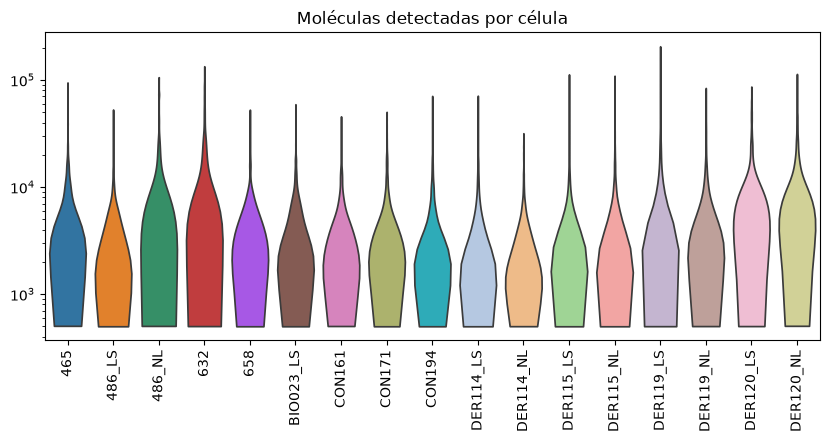

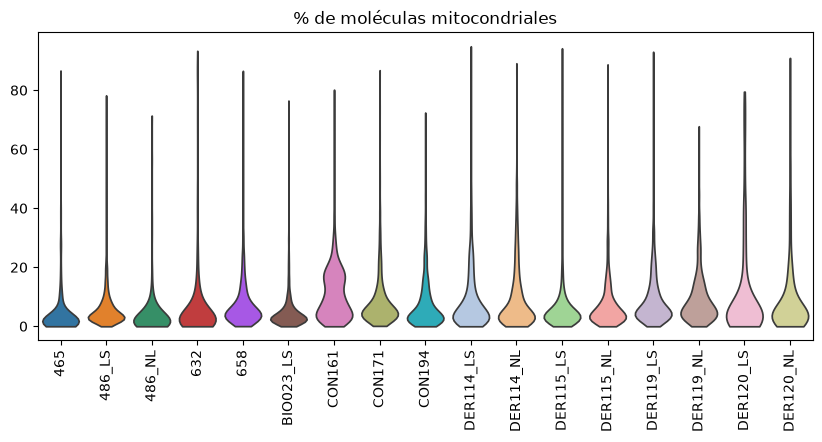

In [4]:
import matplotlib.pyplot as plt

metricas_qc = {
    "n_genes_by_counts": ("Genes detectados por célula", "qc_violin_genes.png"),
    "total_counts": ("Moléculas detectadas por célula", "qc_violin_moleculas.png"),
    "pct_counts_mt": ("% de moléculas mitocondriales", "qc_violin_mt.png"),
}

for metrica, (titulo, archivo) in metricas_qc.items():
    fig, ax = plt.subplots(figsize=(10, 4))
    sc.pl.violin(adata, metrica, groupby="muestra", rotation=90, size=0, ax=ax, show=False)
    ax.set_title(titulo)
    ax.set_xlabel("")
    ax.set_ylabel("")
    if metrica == "total_counts":
        ax.set_yscale("log")
    fig.savefig(DIR_FIGURAS / archivo, dpi=150, bbox_inches="tight")
    plt.show()

In [4]:
def atipico(obs, metrica, nmads):
    """True para las células a más de nmads MADs de la mediana de su muestra."""
    def por_muestra(x):
        mediana = x.median()
        mad = median_abs_deviation(x)
        return (x < mediana - nmads * mad) | (x > mediana + nmads * mad)
    return obs.groupby("muestra", observed=True)[metrica].transform(por_muestra)

adata.obs["atipico"] = (atipico(adata.obs, "log1p_total_counts", 5)
                        | atipico(adata.obs, "log1p_n_genes_by_counts", 5))
adata.obs["atipico_mt"] = (atipico(adata.obs, "pct_counts_mt", 3)
                           | (adata.obs["pct_counts_mt"] > 20))

adata.obs[["atipico", "atipico_mt"]].sum()

atipico        129
atipico_mt    4291
dtype: int64

In [5]:
adata.obs["pasa_qc"] = ~(adata.obs["atipico"] | adata.obs["atipico_mt"])

resumen = (adata.obs.groupby(["condicion", "muestra"], observed=True)["pasa_qc"]
           .agg(antes="size", despues="sum").reset_index())
resumen["eliminadas_pct"] = (100 * (1 - resumen["despues"] / resumen["antes"])).round(1)
print(resumen.to_string(index=False))

condicion   muestra  antes  despues  eliminadas_pct
       LS    486_LS   1345     1138            15.4
       LS BIO023_LS   1249     1045            16.3
       LS DER114_LS   2701     2191            18.9
       LS DER115_LS   3485     3014            13.5
       LS DER119_LS   2699     2199            18.5
       LS DER120_LS    505      380            24.8
       NL    486_NL    200      171            14.5
       NL DER114_NL   2022     1595            21.1
       NL DER115_NL   2483     2046            17.6
       NL DER119_NL   1073      923            14.0
       NL DER120_NL    997      769            22.9
     Sano       465    542      446            17.7
     Sano       632   1106      918            17.0
     Sano       658    593      490            17.4
     Sano    CON161    975      846            13.2
     Sano    CON171   1081      906            16.2
     Sano    CON194   1690     1356            19.8


In [6]:
adata = adata[adata.obs["pasa_qc"]].copy()
sc.pp.filter_genes(adata, min_cells=20)
adata

AnnData object with n_obs × n_vars = 20433 × 21761
    obs: 'donante', 'condicion', 'muestra', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb', 'atipico', 'atipico_mt', 'pasa_qc'
    var: 'gene_ids', 'feature_types', 'mt', 'ribo', 'hb', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells'
    uns: 'muestra_colors'
    layers: None (.X)

In [7]:
sc.pp.scrublet(adata, batch_key="muestra")
print(adata.obs.groupby("muestra", observed=True)["predicted_doublet"].sum())
adata = adata[~adata.obs["predicted_doublet"]].copy()

muestra
465           1
486_LS        4
486_NL        3
632           2
658           1
BIO023_LS     5
CON161        1
CON171        2
CON194        6
DER114_LS    17
DER114_NL     9
DER115_LS     1
DER115_NL     2
DER119_LS     3
DER119_NL     3
DER120_LS     2
DER120_NL     2
Name: predicted_doublet, dtype: int64


In [8]:
resumen.to_csv(DIR_TABLAS / "qc_por_muestra.csv", index=False)
adata.write_h5ad(DIR_PROCESADOS / "02_qc.h5ad")
adata.obs["condicion"].value_counts()

condicion
LS      9935
NL      5485
Sano    4949
Name: count, dtype: int64